In [1]:
import os
from pathlib import Path
from datetime import datetime
import shutil
from hydromt_sfincs import SfincsModel, utils
from hydromt._utils import log
import matplotlib.pyplot as plt

In [3]:
model_root = "trial_semarang_online"
use_subgrid = False

if Path(model_root).exists():
    shutil.rmtree(model_root)

# Initialize logging, the lower the log level number, the more verbose (more info) the output
# NOTSET=0-9, DEBUG=10, INFO=20, WARNING=30, ERROR=40, CRITICAL=50
log.initialize_logging()
log.set_log_level(log_level=20)

# Add file handler to log to a file
log_file = Path(model_root) / "hydromt_sfincs.log"
logger = log._add_filehandler(log_file)

# catalog_path = os.path.join(os.getcwd(),'catalog')
# yaml_path = os.path.join(catalog_path,'data_catalog.yml')
# data_catalog = hydromt.DataCatalog(data_libs=[yaml_path])

# Initialize SfincsModel Python class with the artifact data catalog which contains publically available data for North Italy
sf = SfincsModel(
    data_libs=['deltares_data'],  # specify which data libraries to use
    root=model_root,  # specify the root directory for the model
    mode="w+",  # specify the mode for opening the model (r=read only, r+=append, w=write, w+=overwrite
    write_gis=True,  # specify whether to write GIS data
)

2026-03-03 14:53:45,802 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Reading data catalog deltares_data latest
2026-03-03 14:53:45,802 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from C:\Users\adrie\.hydromt\deltares_data\v1.1.0\data_catalog.yml
2026-03-03 14:53:46,144 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0rc1).
2026-03-03 14:53:46,145 - hydromt.model.model - model - WARNING - No region component found in components.


In [3]:
sf.grid.create_from_region(
    region={"geom": "input/smg.geojson"},  # specify the region geometry
    res=50,  # specify the resolution
    rotated=True,  # specify whether the grid is rotated
    crs="utm",  # specify the coordinate reference system, when "utm", the UTM zone is automatically detected
)


2026-02-23 14:34:19,500 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading smg.geojson GeoDataFrame data from f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\input\smg.geojson
2026-02-23 14:34:19,525 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 9 attributes in model config.


In [4]:
# the input file is automatically updated. See:
sf.config.data.model_dump()

{'mmax': 286,
 'nmax': 213,
 'dx': 50.0,
 'dy': 50.0,
 'x0': 432430.0,
 'y0': 9227031.0,
 'rotation': 15.75,
 'tref': datetime.datetime(2026, 2, 23, 0, 0),
 'tstart': datetime.datetime(2026, 2, 23, 0, 0),
 'tstop': datetime.datetime(2026, 2, 24, 0, 0),
 'tspinup': None,
 't0out': None,
 't1out': None,
 'dtmapout': 3600.0,
 'dtmaxout': 86400.0,
 'dtrstout': None,
 'trstout': None,
 'dthisout': 600.0,
 'dtwave': None,
 'dtwnd': None,
 'alpha': 0.5,
 'theta': 1.0,
 'hmin_cfl': None,
 'manning': None,
 'manning_land': 0.04,
 'manning_sea': 0.02,
 'rgh_lev_land': 0.0,
 'zsini': 0.0,
 'qinf': 0.0,
 'dtmax': None,
 'huthresh': 0.01,
 'rhoa': None,
 'rhow': None,
 'inputformat': 'bin',
 'outputformat': 'net',
 'outputtype_map': None,
 'outputtype_his': None,
 'nc_deflate_level': None,
 'bndtype': None,
 'advection': 1,
 'nfreqsig': None,
 'freqminig': None,
 'freqmaxig': None,
 'latitude': 0.0,
 'pavbnd': None,
 'gapres': None,
 'baro': 1,
 'utmzone': None,
 'epsg': 32749,
 'advlim': None,
 's

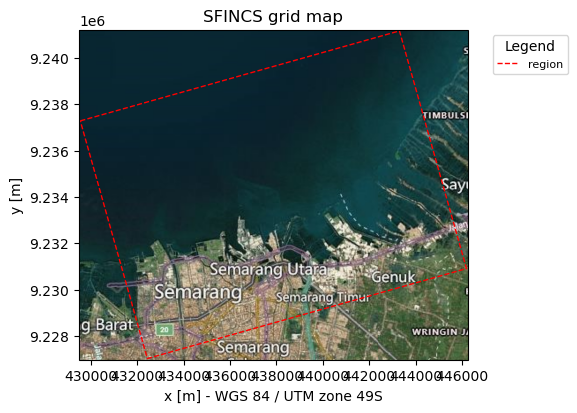

In [5]:
# show the model grid outline
_ = sf.plot_basemap(
    variable="grid",
    plot_region=True,
    bmap="sat",
    zoomlevel=12,
    grid_kwargs={"linewidth": 0.3},
)

2026-02-23 14:34:20,790 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading deltadtm RasterDataset data from F:\TUD_CEG_Repository\MSc_Thesis\Code\trial\catalog\semarang\DeltaDTM.tif
2026-02-23 14:34:21,401 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading gebco RasterDataset data from F:\TUD_CEG_Repository\MSc_Thesis\Code\trial\catalog\semarang\gebco.tif
2026-02-23 14:34:21,818 - hydromt.hydromt_sfincs.components.grid.elevation - elevation - WARNING - Interpolate elevation at 3 cells


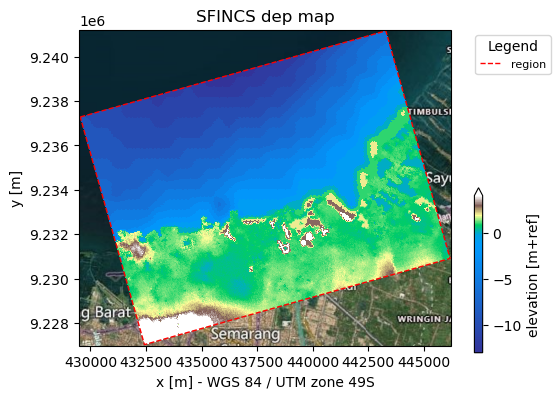

In [6]:
# In this example we want to combine 2 elevation datasets, merit_hydro as elevation and gebco as bathymetry, in that order.
# NOTE: from the 1st dataset (merit_hydro) only elevation above ("zmin":0.001) meters is used;
# the 2nd elevation dataset (gebco) is used where the 1st dataset returned nodata values
# elevation_list = [{"elevation": "merit_hydro", "zmin": 0.001}, {"elevation": "gebco"}]
elevation_list = [{"elevation": "deltadtm", "zmin": 0.001},{"elevation": "gebco"}]

# Add depth information to modelgrid based on these chosen datasets
sf.elevation.create(elevation_list=elevation_list, buffer_cells=1)

# Make a plot of the merged topobathy, here colour limits are set between an elevation of -5 to 5 meters
_ = sf.plot_basemap(variable="dep", plot_region=True, bmap="sat", zoomlevel=12)

2026-02-23 14:34:23,273 - hydromt.hydromt_sfincs.components.grid.mask - mask - INFO - 1 gaps outside valid elevation range < 10.0 km2.
2026-02-23 14:34:23,280 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 2 attributes in model config.


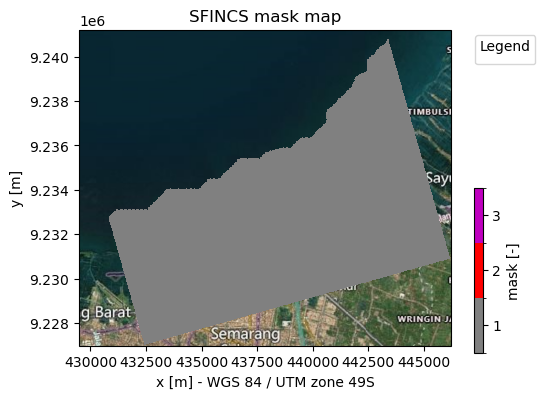

In [7]:
# Defining your active cells can be based on multiple criteria, here we only specify a minimum elevation of -5 meters,
# meaning all cells above -5 are considered to be active. Check-out the method documentation for more options.
sf.mask.create_active(zmin=-5)

# # Make a plot of the mask file
_ = sf.plot_basemap(
    variable="mask", plot_region=False, plot_bounds=True, bmap="sat", zoomlevel=12
)

In [8]:
sf.write()

2026-02-23 14:34:24,738 - hydromt.hydromt_sfincs.components.grid.subgrid - subgrid - INFO - No subgrid table available to write.


In [9]:
# Here we add water level cells along the coastal boundary, for cells up to an elevation of -5 meters
sf.mask.create_boundary(
    btype="waterlevel",
    zmax=-2,
    reset_bounds=True,
)

2026-02-23 14:34:24,783 - hydromt.model.components.grid - grid - WARNING - Replacing grid map: mask


In [10]:
# Here we add outflow cells, only where clicked in shapefile along part of the lateral boundaries
gdf_include = sf.data_catalog.get_geodataframe(
    "input/lateral_smg.geojson"
)
sf.mask.create_boundary(
    btype="outflow",
    include_polygon=gdf_include,
    reset_bounds=True,
)

2026-02-23 14:34:24,792 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading lateral_smg.geojson GeoDataFrame data from f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\input\lateral_smg.geojson
2026-02-23 14:34:24,835 - hydromt.model.components.grid - grid - WARNING - Replacing grid map: mask


<GeoAxes: title={'center': 'SFINCS mask map'}, xlabel='x [m] - WGS 84 / UTM zone 49S', ylabel='y [m]'>

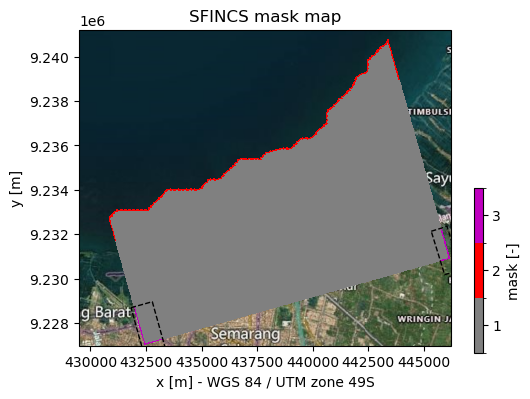

In [11]:
# Make a plot of the mask file
fig, ax = sf.plot_basemap(
    variable="mask", plot_region=False, plot_bounds=False, bmap="sat", zoomlevel=12
)
# plot the shapefile given by the user as dashed line
gdf_include.to_crs(sf.crs).boundary.plot(ax=ax, color="k", lw=1, ls="--")

2026-02-23 14:34:26,029 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading vito_2020 RasterDataset data from F:\TUD_CEG_Repository\MSc_Thesis\Code\trial\catalog\semarang\vito.tif
2026-02-23 14:34:26,050 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading vito_mapping.csv DataFrame data from f:\TUD_CEG_Repository\MSc_Thesis\Data\vito_mapping.csv
2026-02-23 14:34:26,058 - hydromt.gis.raster - raster - WARNING - The nodata value None is not in the reclass table.None will be used for the params.
2026-02-23 14:34:28,039 - hydromt.hydromt_sfincs.components.grid.roughness - roughness - INFO - Set other manning options to None in config that are unused in SFINCS in case of specifying manningfile (manning, manning_land, manning_sea, rgh_lev_land).


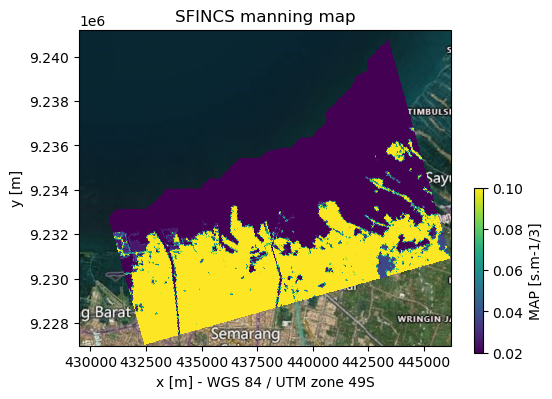

In [12]:
# Some reclass tables are available in the hydromt_sfincs DATADIR
# e.g. vito_mapping.csv for vito_2015 landuse classification
data_dir = r'f:\TUD_CEG_Repository\MSc_Thesis\Data'
reclass_table = os.path.join(data_dir, "vito_mapping.csv")

# use the river manning raster in combination with vito_2015 land to derive the manning roughness file
roughness_list = [{"lulc": "vito_2020", "reclass_table": reclass_table}]

sf.roughness.create(
    roughness_list=roughness_list,
    manning_land=0.04,
    manning_sea=0.02,
    rgh_lev_land=0,  # the minimum elevation of the land
)
_ = sf.plot_basemap(variable="manning", plot_bounds=False, bmap="sat", zoomlevel=12)

In [13]:
if use_subgrid:
    # Repeat elevation and roughness sets for clarity
    elevation_list = [{"elevation": "deltadtm", "zmin": 0.001}, {"elevation": "gebco"}]

    # Roughness sets
    roughness_list = [{"lulc": "vito_2020", "reclass_table": reclass_table}]

    sf.subgrid.create(
        elevation_list=elevation_list,
        roughness_list=roughness_list,
        nr_subgrid_pixels=6,
        write_dep_tif=True,
        write_man_tif=True,
    )

    # NOTE: we turned on that the merged topobathy of the different (high-res) datasets is written to a geotiff

    # uncomment to see the subgrid table variales
    # sf.subgrid.data

    # we can plot the 2D subgrid variables
    _ = sf.plot_basemap(
        variable=sf.subgrid.data["u_navg"], plot_bounds=False, bmap="sat", zoomlevel=12
    )

(<Figure size 600x428.571 with 2 Axes>,
 <GeoAxes: title={'center': 'SFINCS dep map'}, xlabel='x [m] - WGS 84 / UTM zone 49S', ylabel='y [m]'>)

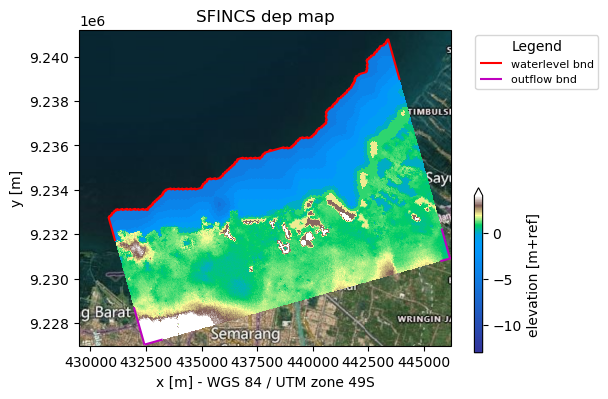

In [14]:
# plot basemap, in this case boundary points should be added (and plotted because of plot_geoms=True)
sf.plot_basemap(
    variable="dep", plot_geoms=True, plot_bounds=True, bmap="sat", zoomlevel=12
)

2026-02-23 14:34:30,667 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 3 attributes in model config.
2026-02-23 14:34:30,859 - hydromt.hydromt_sfincs.components.grid.subgrid - subgrid - INFO - No subgrid table available to write.
2026-02-23 14:34:30,923 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\catalog\data_catalog.yml
2026-02-23 14:34:30,929 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0rc1).
2026-02-23 14:34:30,930 - hydromt.model.model - model - WARNING - No region component found in components.
2026-02-23 14:34:31,382 - hydromt.hydromt_sfincs.components.forcing.boundary_conditions - boundary_conditions - INFO - Removed 5 duplicate points based on 'name' or geometry.


(<Figure size 600x300 with 1 Axes>,
 [<Axes: title={'center': 'SFINCS waterlevel forcing (bzs)'}, ylabel='waterlevel\n[m+ref]'>])

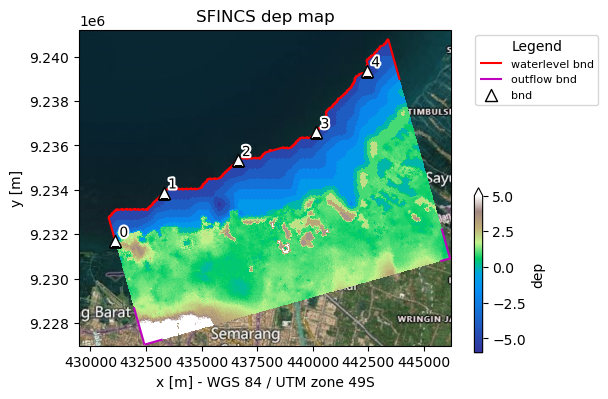

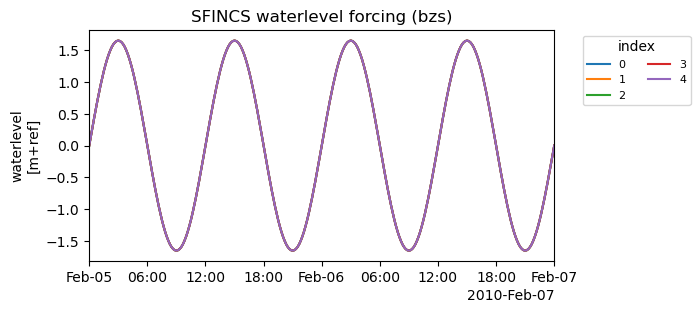

In [15]:
# Change period of model simulation time, specified in yyyymmdd HHMMSS, to match with the available water level data
sf.config.update(
    {
        "tref": datetime(2010, 2, 5),
        "tstart": datetime(2010, 2, 5),
        "tstop": datetime(2010, 2, 7),
    }
)

# From geodataset
# sf.water_level.create(geodataset="gtsmv3_eu_era5")

# sf.discharge_points.add_point(
#     x=436189, y=9237197, value=1000.0, name="Tide?"
# )


sf.water_level.create_boundary_points_from_mask(bnd_dist=5000.0)

# create bc from file
sf.write()
sf = SfincsModel(
    data_libs=yaml_path,  # specify which data libraries to use
    root=model_root,  # specify the root directory for the model
    mode="r+",  # specify the mode for opening the model (r=read only, r+=append, w=write, w+=overwrite
    write_gis=True,  # specify whether to write GIS data
)
bzs_fiiles = r'f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\ts_input_trial.bzs'
wl = sf.water_level.read_boundary_conditions_timeseries(bzs_fiiles)
sf.water_level.create(timeseries=wl*1.1,locations=sf.water_level.gdf)


# # create bc internally
# sf.water_level.create_timeseries(
#     # index=[0],
#     shape="sine",
#     amplitude = 1.5,
#     phase = 0.0,
#     period = 43200.0,
# )


# and plot
sf.plot_basemap(
    variable="dep", plot_geoms=True, plot_bounds=True, bmap="sat", zoomlevel=12
)
sf.plot_forcing()

In [16]:
sf.write()

2026-02-23 14:34:33,374 - hydromt.hydromt_sfincs.components.grid.subgrid - subgrid - INFO - No subgrid table available to write.


In [17]:
src = r"f:\TUD_CEG_Repository\MSc_Thesis\Code\run.bat"
dst = Path(model_root) / 'run.bat'

if not dst.exists():
    shutil.copy(src, dst)

run_path = model_root
cur_dir = os.getcwd()

os.chdir(run_path)
os.system("run.bat")
os.chdir(cur_dir)

In [18]:
# catalog_path = os.path.join(os.getcwd(),'catalog')
# yaml_path = os.path.join(catalog_path,'data_catalog.yml')

mod = SfincsModel(model_root, mode="r")
mod = SfincsModel(model_root, data_libs=[yaml_path], mode="r")
mod.output.read()
list(mod.output.data.keys())

2026-02-23 14:34:55,207 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0rc1).
2026-02-23 14:34:55,208 - hydromt.model.model - model - WARNING - No region component found in components.
2026-02-23 14:34:55,211 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\catalog\data_catalog.yml
2026-02-23 14:34:55,218 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0rc1).
2026-02-23 14:34:55,218 - hydromt.model.model - model - WARNING - No region component found in components.
2026-02-23 14:34:55,405 - hydromt.hydromt_sfincs.components.output - output - WARNING - File F:\TUD_CEG_Repository\MSc_Thesis\Code\trial\trial_semarang\sfincs_his.nc not found.
2026-02-23 14:34:55,406 - hydromt.hydromt_sfincs.components.output - output - WARNING - Replacing result: inp
2026-02-23 14:34:55,406 - hydromt.hydromt_sfincs.components.output - output 

['inp',
 'msk',
 'zb',
 'zs',
 'h',
 'zsmax',
 'hmax',
 'total_runtime',
 'average_dt',
 'status']

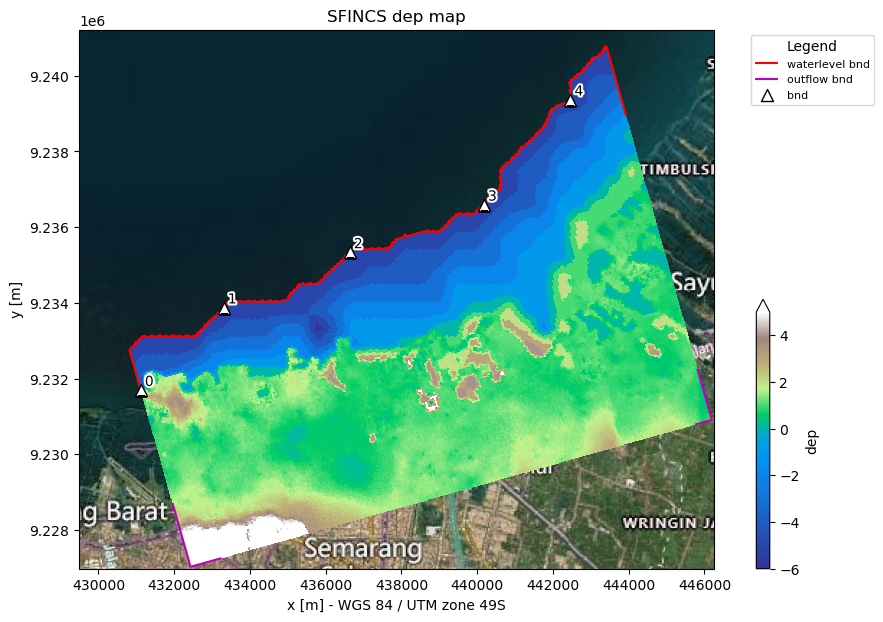

In [19]:
# plot the model layout
fig, ax = mod.plot_basemap(fn_out=None, bmap="sat", figsize=(11, 7))

In [20]:
# read global surface water occurance (GSWO) data to mask permanent water
gswo = mod.data_catalog.get_rasterdataset("gswo", geom=mod.region, buffer=10)


hmin = 0.05  # minimum flood depth [m] to plot

if Path(model_root+'/subgrid').exists():
    # first we are going to select our highest-resolution elevation dataset
    depfile = os.path.join(model_root, "subgrid", "dep_subgrid.tif")
    da_dep = mod.data_catalog.get_rasterdataset(depfile)
    
    # secondly we are reading in the model results
    da_zsmax = mod.output.data["zsmax"].max(dim="timemax")

    # Fourthly, we downscale the floodmap
    da_hmax = utils.downscale_floodmap(
        zsmax=da_zsmax,
        dep=da_dep,
        hmin=hmin,
        # gdf_mask=gdf,
        # floodmap_fn=os.path.join(model_root, "floodmap.tif") # uncomment to save to <mod.root>/floodmap.tif
    )
    gswo_mask = gswo.raster.reproject_like(da_dep, method="max") <= 5

    da_hmax = da_hmax.where(gswo_mask).where(da_hmax > hmin)

else:
    # permanent water where water occurence > 5%
    gswo_mask = gswo.raster.reproject_like(mod.grid.data, method="max") <= 5

    # hmax is computed by SFINCS and read-in from the sfincs_map.nc file
    da_hmax = mod.output.data["hmax"].max(dim="timemax")

    # get overland flood depth with GSWO and set minimum flood depth
    da_hmax = da_hmax.where(gswo_mask).where(da_hmax > hmin)

# update attributes for colorbar label later
da_hmax.attrs.update(long_name="flood depth", unit="m")

2026-02-23 14:34:56,920 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading gswo RasterDataset data from F:\TUD_CEG_Repository\MSc_Thesis\Code\trial\catalog\semarang\gswo.tif


Text(0.5, 1.0, 'SFINCS maximum water depth')

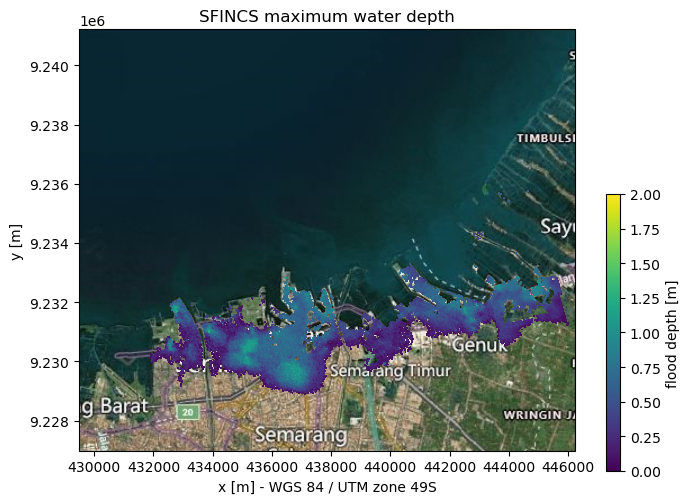

In [21]:
# create hmax plot and save to mod.root/figs/hmax.png
fig, ax = mod.plot_basemap(
    fn_out=None,
    figsize=(8, 6),
    variable=da_hmax,
    plot_bounds=False,
    plot_geoms=False,
    bmap="sat",
    zoomlevel=12,
    vmin=0,
    vmax=2.0,
    cmap=plt.cm.viridis,
    cbar_kwargs={"shrink": 0.6, "anchor": (0, 0)},
)
ax.set_title(f"SFINCS maximum water depth")
# plt.savefig(join(mod.root, 'figs', 'hmax.png'), dpi=225, bbox_inches="tight")

In [22]:
log.logging.shutdown()

In [23]:
sf.elevation.data['dep']

<xarray.DataArray 'dep' (y: 213, x: 286)> Size: 244kB
array([[ 1.7916685e+01,  1.8901066e+01,  1.9692818e+01, ...,
         1.0980669e+00,  8.9012676e-01,  8.9568806e-01],
       [ 1.6351364e+01,  1.6306864e+01,  1.6554291e+01, ...,
         8.5407889e-01,  8.4252399e-01,  9.3459988e-01],
       [ 1.7856560e+01,  1.4970164e+01,  1.4982578e+01, ...,
         6.5757865e-01,  7.4186516e-01,  9.1269684e-01],
       ...,
       [-9.9990000e+03, -9.9990000e+03, -9.9990000e+03, ...,
        -9.9990000e+03, -9.9990000e+03, -9.9990000e+03],
       [-9.9990000e+03, -9.9990000e+03, -9.9990000e+03, ...,
        -9.9990000e+03, -9.9990000e+03, -9.9990000e+03],
       [-9.9990000e+03, -9.9990000e+03, -9.9990000e+03, ...,
        -9.9990000e+03, -9.9990000e+03, -9.9990000e+03]],
      shape=(213, 286), dtype=float32)
Coordinates:
    yc           (y, x) float64 487kB 9.227e+06 9.227e+06 ... 9.241e+06
    xc           (y, x) float64 487kB 4.324e+05 4.325e+05 ... 4.433e+05
    spatial_ref  int64 8B 0
Dimensions without coordinates: y, x
Attributes:
    _FillValue:  nan

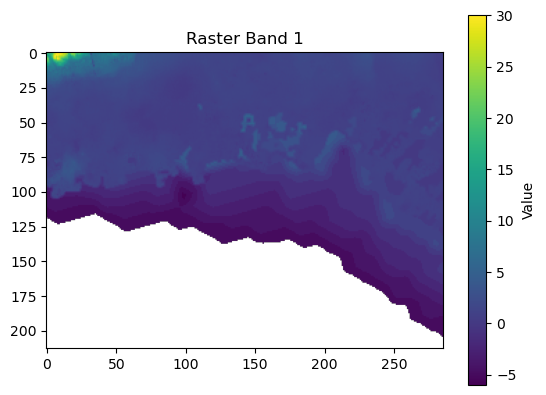

In [24]:
import rasterio
from rasterio.plot import show
dep_tif = r'f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\trial_semarang\gis\dep.tif'
dep_file = r'f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\trial_semarang\sfincs.dep'
with rasterio.open(dep_tif) as src:
    data = src.read(1)  # read first band
    plt.imshow(data, cmap="viridis")
    plt.colorbar(label="Value")
    plt.title("Raster Band 1")
    plt.show()
    # show(src)

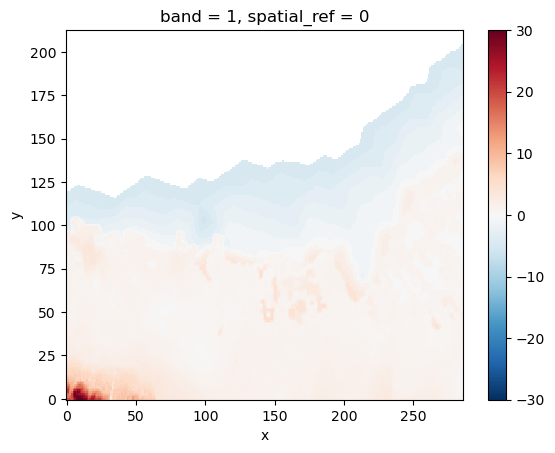

In [25]:
import rioxarray
import matplotlib.pyplot as plt

ds = rioxarray.open_rasterio(dep_tif)

ds.plot()
plt.show()

In [28]:
import numpy as np

mmax = 286   # from sfincs.inp
nmax = 213   # from sfincs.inp

dep = np.fromfile(dep_file, dtype="float32")
dep
# dep = dep.reshape((nmax, mmax))

array([17.916685, 16.351364, 17.85656 , ..., -5.      , -5.      ,
       -5.      ], shape=(40879,), dtype=float32)

In [30]:
40879/213

191.92018779342723